# Food Demand: Exploratory Analysis and Statistical Tests

This notebook answers Tasks 3–6 using only the prepared training observations in `data/processed/prepared_train.csv`. The test set is not used because it has no observed `num_orders`. The notebook computes descriptive demand and business metrics, creates reproducible figures and summary tables, and reports exploratory statistical associations without making causal claims.

The Task 2 cleaning log identifies 222 meal-week pairs not observed within weeks 1–145. These absences are not filled with zero: the available data cannot establish whether a meal was offered in each missing week. Consequently, volatility summaries use each meal's observed weeks and report coverage.

## 0. Load and validate the prepared dataset

Confirm the prepared file, required fields, missingness, and integrity totals before aggregation. The reported promotion indicators are kept distinct: `emailer_for_promotion` records email promotion and `homepage_featured` records homepage placement.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, rankdata, spearmanr
from scipy.special import log_ndtr
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next((path for path in candidates if (path / 'data' / 'processed' / 'prepared_train.csv').is_file()), None)
if project_root is None:
    raise FileNotFoundError('Could not find data/processed/prepared_train.csv from the notebook working directory.')
prepared_path = project_root / 'data' / 'processed' / 'prepared_train.csv'
data = pd.read_csv(prepared_path)
required = {'week', 'center_id', 'meal_id', 'num_orders', 'checkout_price', 'base_price',
            'emailer_for_promotion', 'homepage_featured', 'center_type', 'category', 'cuisine'}
missing_columns = required - set(data.columns)
if missing_columns:
    raise ValueError(f'Prepared dataset is missing required columns: {sorted(missing_columns)}')
if data[list(required)].isna().any().any():
    missing_counts = data[list(required)].isna().sum()
    raise ValueError(f'Missing values found in required analysis columns: {missing_counts[missing_counts.gt(0)].to_dict()}')
if not data['emailer_for_promotion'].isin([0, 1]).all() or not data['homepage_featured'].isin([0, 1]).all():
    raise ValueError('Promotion indicators must be binary 0/1 values.')
if (data['base_price'] <= 0).any():
    print('Warning: non-positive base_price rows will be excluded from discount calculations and reported.')

figures_dir = project_root / 'reports' / 'figures'
reports_dir = project_root / 'reports'
figures_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)
row_count = len(data)
total_orders = int(data['num_orders'].sum())
observed_weeks = int(data['week'].nunique())
print(f'Prepared observations: {row_count:,}')
print(f'Total num_orders: {total_orders:,}')
print(f'Observed weeks: {observed_weeks:,} ({data.week.min()}–{data.week.max()})')
print(f'Meals: {data.meal_id.nunique():,}; fulfillment centers: {data.center_id.nunique():,}')
print('Prepared data types:', {column: str(dtype) for column, dtype in data.dtypes.items()})
print('Missing values by column:', data.isna().sum().to_dict())
assert row_count == 456_548 and total_orders == 119_557_485, 'Prepared data integrity differs from the verified Task 2 output.'
print('Integrity check passed against Task 2 prepared-data totals.')

Prepared observations: 456,548
Total num_orders: 119,557,485
Observed weeks: 145 (1–145)
Meals: 51; fulfillment centers: 77
Prepared data types: {'id': 'int64', 'week': 'int64', 'center_id': 'int64', 'meal_id': 'int64', 'checkout_price': 'float64', 'base_price': 'float64', 'emailer_for_promotion': 'int64', 'homepage_featured': 'int64', 'num_orders': 'int64', 'city_code': 'int64', 'region_code': 'int64', 'center_type': 'str', 'op_area': 'float64', 'category': 'str', 'cuisine': 'str'}
Missing values by column: {'id': 0, 'week': 0, 'center_id': 0, 'meal_id': 0, 'checkout_price': 0, 'base_price': 0, 'emailer_for_promotion': 0, 'homepage_featured': 0, 'num_orders': 0, 'city_code': 0, 'region_code': 0, 'center_type': 0, 'op_area': 0, 'category': 0, 'cuisine': 0}
Integrity check passed against Task 2 prepared-data totals.


## Q1. Weekly demand

Weekly demand is the sum of `num_orders` across all observed meal-center records in each week. The average is the mean of these observed weekly totals. The line chart describes the observed pattern; it does not identify why demand changes.

Average demand per observed week: 824,534.38 orders across 145 weeks.
Highest-demand week(s):


,week,total_orders
47,48,1303457


Lowest-demand week(s):


,week,total_orders
61,62,380065


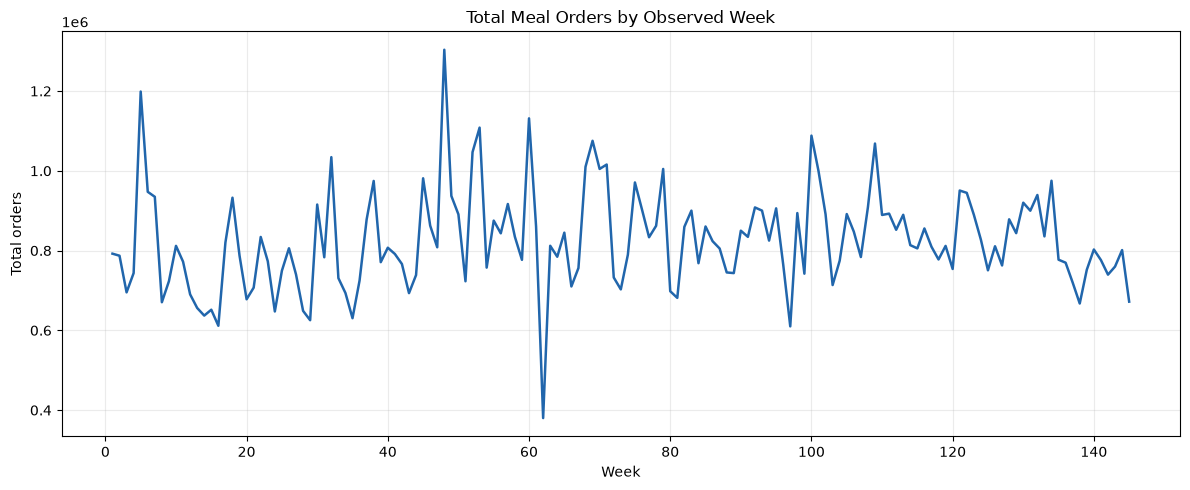

In [2]:
weekly_demand = data.groupby('week', as_index=False)['num_orders'].sum().rename(columns={'num_orders': 'total_orders'})
assert int(weekly_demand['total_orders'].sum()) == total_orders, 'Weekly aggregation does not reconcile to the prepared-data total.'
average_weekly_demand = weekly_demand['total_orders'].mean()
max_week_rows = weekly_demand.loc[weekly_demand['total_orders'].eq(weekly_demand['total_orders'].max())]
min_week_rows = weekly_demand.loc[weekly_demand['total_orders'].eq(weekly_demand['total_orders'].min())]
print(f'Average demand per observed week: {average_weekly_demand:,.2f} orders across {len(weekly_demand):,} weeks.')
print('Highest-demand week(s):')
display(max_week_rows)
print('Lowest-demand week(s):')
display(min_week_rows)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly_demand['week'], weekly_demand['total_orders'], color='#2166ac', linewidth=1.8)
ax.set(title='Total Meal Orders by Observed Week', xlabel='Week', ylabel='Total orders')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / 'weekly_demand.png', dpi=160)
plt.show()
weekly_demand.to_csv(reports_dir / 'weekly_demand.csv', index=False)

## Q2. Categories and meals contributing to 80% of demand

Categories and meals are ranked by total observed orders. Cumulative share is calculated from the overall order total. The selected set is the smallest leading prefix whose cumulative share reaches or exceeds 80%; this is a descriptive concentration threshold, not evidence of a causal relationship.

Categories needed to reach at least 80%: 5 of 14; orders=97,319,426; share=81.40%.


,category,total_orders,demand_share,cumulative_share
0,Beverages,40480525,0.338586,0.338586
1,Rice Bowl,20874063,0.174594,0.513181
2,Sandwich,17636782,0.147517,0.660698
3,Salad,10944336,0.091540,0.752238
4,Pizza,7383720,0.061759,0.813997


Meals needed to reach at least 80%: 22 of 51; orders=97,058,907; share=81.18%.


,meal_id,category,cuisine,total_orders,demand_share,cumulative_share
0,2290,Rice Bowl,Indian,9770303,0.081721,0.081721
1,1885,Beverages,Thai,8346246,0.069809,0.151530
2,1754,Sandwich,Italian,6818059,0.057027,0.208557
3,1993,Beverages,Thai,6656856,0.055679,0.264237
4,1109,Rice Bowl,Indian,6367773,0.053261,0.317498
5,2707,Beverages,Italian,5932792,0.049623,0.367121
6,1971,Sandwich,Italian,5728620,0.047915,0.415036
7,2826,Sandwich,Italian,5090103,0.042575,0.457610
8,1727,Rice Bowl,Indian,4735987,0.039613,0.497223
9,1062,Beverages,Italian,4712795,0.039419,0.536642


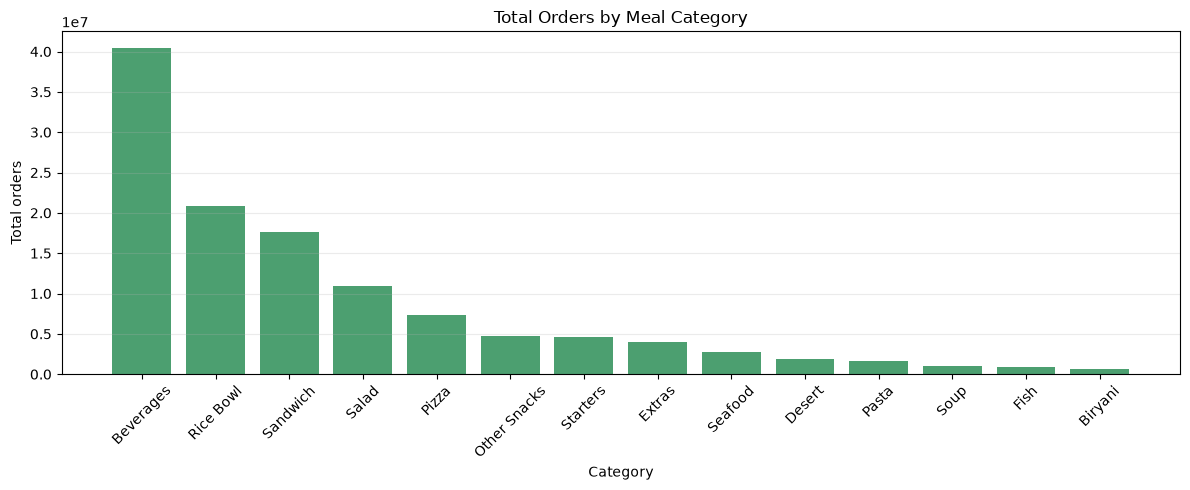

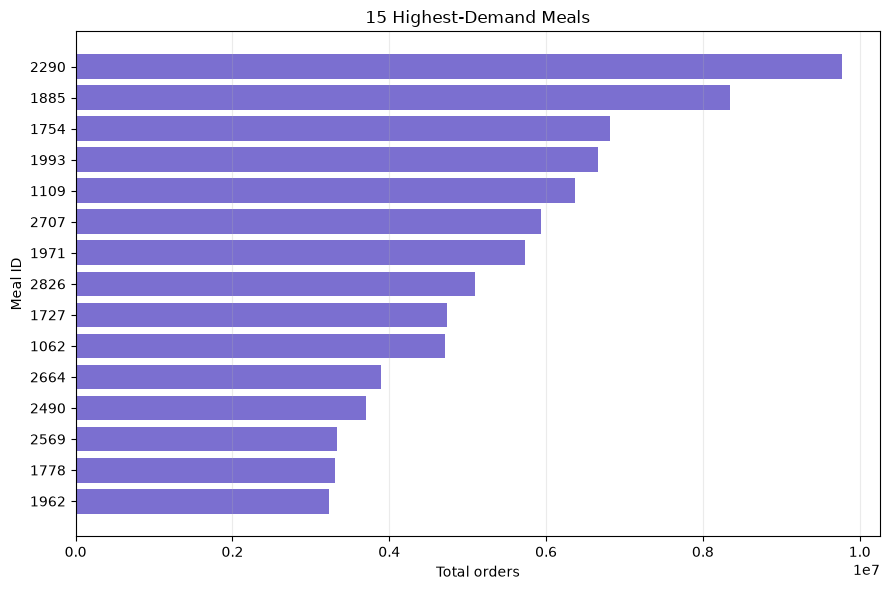

In [3]:
category_demand = (data.groupby('category', as_index=False)['num_orders'].sum()
                   .rename(columns={'num_orders': 'total_orders'})
                   .sort_values(['total_orders', 'category'], ascending=[False, True]).reset_index(drop=True))
category_demand['demand_share'] = category_demand['total_orders'] / total_orders
category_demand['cumulative_share'] = category_demand['demand_share'].cumsum()
category_demand['reaches_80_percent'] = category_demand['cumulative_share'].shift(fill_value=0).lt(0.80)
category_selected = category_demand.loc[category_demand['reaches_80_percent']].copy()
meal_demand = (data.groupby(['meal_id', 'category', 'cuisine'], as_index=False)['num_orders'].sum()
               .rename(columns={'num_orders': 'total_orders'})
               .sort_values(['total_orders', 'meal_id'], ascending=[False, True]).reset_index(drop=True))
meal_demand['demand_share'] = meal_demand['total_orders'] / total_orders
meal_demand['cumulative_share'] = meal_demand['demand_share'].cumsum()
meal_demand['reaches_80_percent'] = meal_demand['cumulative_share'].shift(fill_value=0).lt(0.80)
meal_selected = meal_demand.loc[meal_demand['reaches_80_percent']].copy()
assert int(category_demand['total_orders'].sum()) == total_orders
assert int(meal_demand['total_orders'].sum()) == total_orders
print(f'Categories needed to reach at least 80%: {len(category_selected)} of {len(category_demand)}; orders={int(category_selected.total_orders.sum()):,}; share={category_selected.demand_share.sum():.2%}.')
display(category_selected[['category', 'total_orders', 'demand_share', 'cumulative_share']])
print(f'Meals needed to reach at least 80%: {len(meal_selected)} of {len(meal_demand)}; orders={int(meal_selected.total_orders.sum()):,}; share={meal_selected.demand_share.sum():.2%}.')
display(meal_selected[['meal_id', 'category', 'cuisine', 'total_orders', 'demand_share', 'cumulative_share']])

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(category_demand['category'], category_demand['total_orders'], color='#4c9f70')
ax.set(title='Total Orders by Meal Category', xlabel='Category', ylabel='Total orders')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / 'category_demand.png', dpi=160)
plt.show()

top_meals = meal_demand.head(15).sort_values('total_orders')
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_meals['meal_id'].astype(str), top_meals['total_orders'], color='#7b6fd0')
ax.set(title='15 Highest-Demand Meals', xlabel='Total orders', ylabel='Meal ID')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / 'top_meals_demand.png', dpi=160)
plt.show()
category_demand.to_csv(reports_dir / 'category_demand.csv', index=False)
meal_demand.to_csv(reports_dir / 'meal_total_demand.csv', index=False)

## Q3. Fulfilment center performance by center type

The first summary reports total orders and their share by center type. Center totals alone can reflect different observation exposure, so the center-level comparison also reports each center's observed row count, number of observed weeks, total orders, and average weekly orders over its own observed weeks. All centers have 145 observed weeks except one with 120; the average uses each center's actual observed-week count. It is not adjusted for operating area or business mix.

Observed weeks per center: min=120, max=145; centers with fewer than all 145 observed weeks=1.
Centers with shorter coverage: {24: 120}
Order totals and shares by center type:


,center_type,total_orders,centers,observed_rows,observed_weeks,order_share
0,TYPE_A,68978517,43,262881,145,0.576949
1,TYPE_B,29996073,15,94074,145,0.250892
2,TYPE_C,20582895,19,99593,145,0.172159


Five centers with highest average orders per observed week:


,center_id,center_type,total_orders,observation_count,observed_weeks,average_orders_per_observed_week
2,13,TYPE_B,4296545,7046,145,29631.344828
18,43,TYPE_A,3920294,6970,145,27036.510345
0,10,TYPE_B,3381018,7015,145,23317.365517
21,52,TYPE_B,3125835,6993,145,21557.482759
63,137,TYPE_A,3117478,6894,145,21499.848276


Five centers with lowest average orders per observed week:


,center_id,center_type,total_orders,observation_count,observed_weeks,average_orders_per_observed_week
35,74,TYPE_A,691044,5264,145,4765.820690
73,162,TYPE_C,680255,4366,145,4691.413793
68,149,TYPE_A,637527,5021,145,4396.737931
16,41,TYPE_C,497338,4083,145,3429.917241
45,91,TYPE_C,425160,3432,145,2932.137931


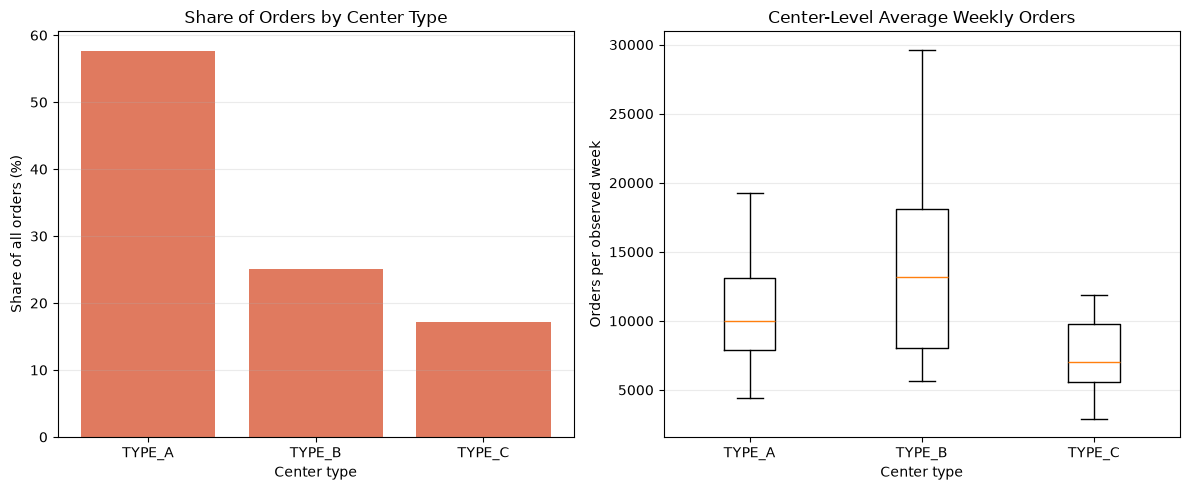

In [4]:
center_type_summary = (data.groupby('center_type', as_index=False)
                       .agg(total_orders=('num_orders', 'sum'), centers=('center_id', 'nunique'),
                            observed_rows=('num_orders', 'size'), observed_weeks=('week', 'nunique')))
center_type_summary['order_share'] = center_type_summary['total_orders'] / total_orders
center_summary = (data.groupby(['center_id', 'center_type'], as_index=False)
                  .agg(total_orders=('num_orders', 'sum'), observation_count=('num_orders', 'size'),
                       observed_weeks=('week', 'nunique')))
center_summary['average_orders_per_observed_week'] = center_summary['total_orders'] / center_summary['observed_weeks']
center_summary = center_summary.sort_values(['average_orders_per_observed_week', 'center_id'], ascending=[False, True])
center_week_coverage = data.groupby('center_id')['week'].nunique()
print(f'Observed weeks per center: min={center_week_coverage.min()}, max={center_week_coverage.max()}; centers with fewer than all {observed_weeks} observed weeks={int(center_week_coverage.lt(observed_weeks).sum())}.')
if center_week_coverage.lt(observed_weeks).any():
    print('Centers with shorter coverage:', center_week_coverage.loc[center_week_coverage.lt(observed_weeks)].to_dict())
assert int(center_type_summary['total_orders'].sum()) == total_orders
print('Order totals and shares by center type:')
display(center_type_summary.sort_values('total_orders', ascending=False))
print('Five centers with highest average orders per observed week:')
display(center_summary.head(5))
print('Five centers with lowest average orders per observed week:')
display(center_summary.tail(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ordered_types = center_type_summary.sort_values('order_share', ascending=False)
axes[0].bar(ordered_types['center_type'], ordered_types['order_share'] * 100, color='#e07a5f')
axes[0].set(title='Share of Orders by Center Type', xlabel='Center type', ylabel='Share of all orders (%)')
axes[0].grid(axis='y', alpha=0.25)
type_order = sorted(center_summary['center_type'].unique())
box_data = [center_summary.loc[center_summary['center_type'].eq(kind), 'average_orders_per_observed_week'] for kind in type_order]
axes[1].boxplot(box_data, tick_labels=type_order, showfliers=False)
axes[1].set(title='Center-Level Average Weekly Orders', xlabel='Center type', ylabel='Orders per observed week')
axes[1].grid(axis='y', alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / 'center_type_performance.png', dpi=160)
plt.show()
center_type_summary.to_csv(reports_dir / 'center_type_demand.csv', index=False)
center_summary.to_csv(reports_dir / 'fulfilment_center_demand.csv', index=False)

## Business metrics and meal demand volatility

- **Total orders** are the sum of observed `num_orders`.
- **Average weekly demand** is total orders divided by the number of observed weeks.
- **Estimated revenue** is the sum of `checkout_price × num_orders`; it is an estimate based on the recorded checkout price, not audited financial revenue.
- **Average signed discount rate** is the unweighted mean across valid rows of `(base_price - checkout_price) / base_price`. Each row receives equal weight, irrespective of order volume. Invalid or non-positive base prices are excluded and counted; prices above base price remain negative discount rates and are not clipped to zero.
- **Promotion row percentages** count rows with each binary indicator equal to 1. Email promotion and homepage featuring are separate indicators and may overlap.
- **Meal demand volatility (CV)** is the sample standard deviation (`ddof=1`) of a meal's weekly summed orders divided by its mean weekly summed orders, calculated only over weeks in which that meal has an observed row. Missing meal-weeks are not imputed as zero; coverage varies and affects comparability.

In [5]:
valid_base_price = data['base_price'].gt(0) & np.isfinite(data['base_price'])
discount_rate = (data.loc[valid_base_price, 'base_price'] - data.loc[valid_base_price, 'checkout_price']) / data.loc[valid_base_price, 'base_price']
weekly_meal_demand = (data.groupby(['meal_id', 'week'], as_index=False)['num_orders'].sum()
                      .rename(columns={'num_orders': 'weekly_orders'}))
meal_week_stats = (weekly_meal_demand.groupby('meal_id')['weekly_orders']
                   .agg(mean_weekly_orders='mean', sd_weekly_orders=lambda values: values.std(ddof=1), observed_weeks='count')
                   .reset_index())
meal_week_stats['cv'] = meal_week_stats['sd_weekly_orders'] / meal_week_stats['mean_weekly_orders'].where(meal_week_stats['mean_weekly_orders'].ne(0))
print(f'Total orders: {total_orders:,}')
print(f'Average weekly demand: {average_weekly_demand:,.2f} orders ({observed_weeks} observed weeks).')
estimated_revenue = float((data['checkout_price'] * data['num_orders']).sum())
print(f'Estimated revenue at recorded checkout prices: {estimated_revenue:,.2f} (price units not independently audited).')
invalid_base_rows = int((~valid_base_price).sum())
negative_discount_rows = int(discount_rate.lt(0).sum())
zero_discount_rows = int(discount_rate.eq(0).sum())
print(f'Average row-weighted signed discount rate: {discount_rate.mean():.2%}; valid rows={len(discount_rate):,}; excluded invalid/non-positive base-price rows={invalid_base_rows:,}.')
print(f'Negative rates retained (checkout_price > base_price): {negative_discount_rows:,} ({negative_discount_rows / len(data):.2%}); exact zero rates: {zero_discount_rows:,}. Negative rates are not replaced by zero.')
print(f'Rows with checkout_price > base_price: {int(data.checkout_price.gt(data.base_price).sum()):,}; these contribute negative rates to the mean.')
for flag in ['emailer_for_promotion', 'homepage_featured']:
    count = int(data[flag].eq(1).sum())
    print(f'{flag}=1: {count:,} rows ({count / row_count:.2%}).')
print(f'Meal-week observations: {len(weekly_meal_demand):,}; possible meal-week combinations over observed range: {data.meal_id.nunique() * observed_weeks:,}; unobserved combinations: {data.meal_id.nunique() * observed_weeks - len(weekly_meal_demand):,}.')
print('Weekly demand standard deviation uses ddof=1. CV is undefined for zero mean and is not computed for that case.')
display(meal_week_stats.sort_values('mean_weekly_orders', ascending=False).head(5))
weekly_meal_demand.to_csv(reports_dir / 'meal_weekly_demand.csv', index=False)

Total orders: 119,557,485
Average weekly demand: 824,534.38 orders (145 observed weeks).
Estimated revenue at recorded checkout prices: 31,922,771,040.11 (price units not independently audited).
Average row-weighted signed discount rate: 5.72%; valid rows=456,548; excluded invalid/non-positive base-price rows=0.
Negative rates retained (checkout_price > base_price): 116,101 (25.43%); exact zero rates: 110,760. Negative rates are not replaced by zero.
Rows with checkout_price > base_price: 116,101; these contribute negative rates to the mean.
emailer_for_promotion=1: 37,050 rows (8.12%).
homepage_featured=1: 49,855 rows (10.92%).
Meal-week observations: 7,173; possible meal-week combinations over observed range: 7,395; unobserved combinations: 222.
Weekly demand standard deviation uses ddof=1. CV is undefined for zero mean and is not computed for that case.


,meal_id,mean_weekly_orders,sd_weekly_orders,observed_weeks,cv
30,2290,67381.400000,60641.916250,145,0.899980
22,1885,57560.317241,10998.041724,145,0.191070
16,1754,47021.096552,41698.021104,145,0.886794
26,1993,45909.351724,10707.705831,145,0.233236
1,1109,43915.675862,24620.199675,145,0.560624


## Q4. Demand with and without promotional indicators

The primary comparison is `emailer_for_promotion`; `homepage_featured` is analyzed separately and is not treated as the same intervention. For each indicator, only meal-center pairs observed with both flag values are retained, so the comparison is within combinations with common support. Descriptive statistics and a two-sided Mann–Whitney U test compare row-level order counts.

**Hypotheses:** for each indicator, the two-sided Mann–Whitney null is that order counts in the eligible indicator=1 and indicator=0 groups come from the same distribution; the alternative is that their distributions differ. The eligible weekly rows are pooled across all qualifying meal-center pairs; this is a row-weighted comparison, not a paired test or an equal-weight average of pair-level effects. **Important limitation:** each meal-center combination is observed repeatedly across weeks. The ordinary Mann–Whitney test treats rows as independent, which is not justified by this repeated-measures structure. The reported p-values are therefore naive, exploratory reference values, not reliable confirmatory inference. Mean differences and Cliff's delta are descriptive associations, not causal effects. Promotions may coincide with price discounts, featured placement, seasonality, and other factors.


emailer_for_promotion: common-support meal-center pairs=2,830; excluded pairs=767.
Row sample sizes: no=338,694, yes=37,050; U=8,740,582,324.50; naive two-sided p=< 1e-300 (asymptotic log10 p=-3364.14; scipy float underflow).
Mean orders: no=254.643, yes=631.098; percent difference relative to no-promotion mean=147.84%.
Cliff's delta (probability superiority effect, ties split): 0.3931.

homepage_featured: common-support meal-center pairs=2,928; excluded pairs=669.
Row sample sizes: no=338,548, yes=49,855; U=11,694,179,707.50; naive two-sided p=< 1e-300 (asymptotic log10 p=-4214.30; scipy float underflow).
Mean orders: no=241.373, yes=594.885; percent difference relative to no-promotion mean=146.46%.
Cliff's delta (probability superiority effect, ties split): 0.3857.


,indicator,promotion,n,eligible_meal_center_pairs,mean_orders,median_orders,sd_orders,q25_orders,q75_orders,U_statistic,p_value_report,p_value_holm_report,mean_difference_percent,cliffs_delta
0,emailer_for_promotion,No,338694,2830,254.642539,149.0,314.999189,67.0,337.0,8.740582e+09,< 1e-300 (log10 p≈-3364.14; scipy float underf...,< 1e-300 (Holm log10 p≈-3364.14),147.836653,0.393075
1,emailer_for_promotion,Yes,37050,2830,631.097544,338.0,886.153796,161.0,742.0,8.740582e+09,< 1e-300 (log10 p≈-3364.14; scipy float underf...,< 1e-300 (Holm log10 p≈-3364.14),147.836653,0.393075
2,homepage_featured,No,338548,2928,241.372937,148.0,305.421817,55.0,312.0,1.169418e+10,< 1e-300 (log10 p≈-4214.30; scipy float underf...,< 1e-300 (Holm log10 p≈-4214.00),146.458776,0.385705
3,homepage_featured,Yes,49855,2928,594.884786,350.0,790.036459,136.0,743.0,1.169418e+10,< 1e-300 (log10 p≈-4214.30; scipy float underf...,< 1e-300 (Holm log10 p≈-4214.00),146.458776,0.385705


Holm adjustment covers the two exploratory indicator-level tests only; it does not correct dependence among repeated weekly rows.


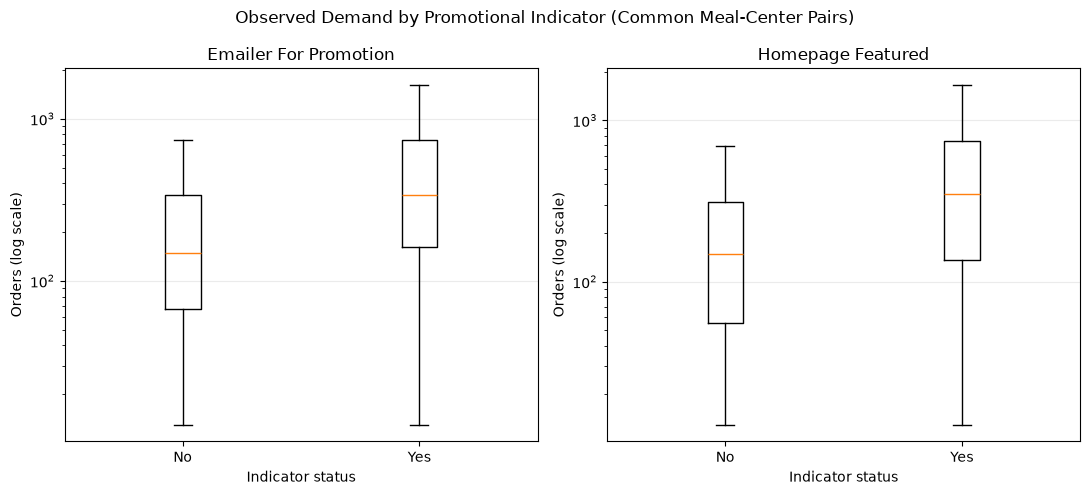

In [6]:
promotion_results = []
promotion_plot_data = {}
for flag in ['emailer_for_promotion', 'homepage_featured']:
    pair_status_counts = data.groupby(['meal_id', 'center_id'])[flag].nunique()
    eligible_pairs = pair_status_counts.index[pair_status_counts.eq(2)]
    pair_index = pd.MultiIndex.from_frame(data[['meal_id', 'center_id']])
    eligible_mask = pair_index.isin(eligible_pairs)
    eligible = data.loc[eligible_mask, ['meal_id', 'center_id', 'week', flag, 'num_orders']]
    no_promo = eligible.loc[eligible[flag].eq(0), 'num_orders'].to_numpy()
    promo = eligible.loc[eligible[flag].eq(1), 'num_orders'].to_numpy()
    if len(no_promo) == 0 or len(promo) == 0:
        raise ValueError(f'Both flag groups are required for the {flag} comparison.')
    test = mannwhitneyu(promo, no_promo, alternative='two-sided', method='asymptotic', use_continuity=True)
    pooled_orders = np.concatenate([promo, no_promo])
    _, tie_counts = np.unique(pooled_orders, return_counts=True)
    tie_term = np.sum(tie_counts ** 3 - tie_counts)
    n_promo, n_no_promo = len(promo), len(no_promo)
    pooled_n = n_promo + n_no_promo
    u_variance = n_promo * n_no_promo / 12 * (pooled_n + 1 - tie_term / (pooled_n * (pooled_n - 1)))
    z_abs = max(0.0, abs(float(test.statistic) - n_promo * n_no_promo / 2) - 0.5) / np.sqrt(u_variance)
    log_p_asymptotic = np.log(2) + log_ndtr(-z_abs)
    log10_p_asymptotic = float(log_p_asymptotic / np.log(10))
    baseline_mean = float(no_promo.mean())
    mean_difference_pct = (float(promo.mean()) - baseline_mean) / baseline_mean * 100 if baseline_mean != 0 else np.nan
    cliff_delta = 2 * float(test.statistic) / (len(promo) * len(no_promo)) - 1
    for value, label in [(no_promo, 'No'), (promo, 'Yes')]:
        promotion_results.append({'indicator': flag, 'promotion': label, 'n': len(value), 'mean_orders': float(value.mean()),
                                  'median_orders': float(np.median(value)), 'sd_orders': float(np.std(value, ddof=1)),
                                  'q25_orders': float(np.quantile(value, 0.25)), 'q75_orders': float(np.quantile(value, 0.75)),
                                  'eligible_meal_center_pairs': len(eligible_pairs), 'U_statistic': float(test.statistic),
                                  'p_value_naive': float(test.pvalue), 'p_value_log10_asymptotic': log10_p_asymptotic,
                                  'mean_difference_percent': mean_difference_pct,
                                  'cliffs_delta': cliff_delta})
    promotion_plot_data[flag] = (no_promo, promo)
    print(f'\n{flag}: common-support meal-center pairs={len(eligible_pairs):,}; excluded pairs={len(pair_status_counts) - len(eligible_pairs):,}.')
    p_display = f'< 1e-300 (asymptotic log10 p={log10_p_asymptotic:.2f}; scipy float underflow)' if test.pvalue == 0 else f'{test.pvalue:.6g}'
    print(f'Row sample sizes: no={len(no_promo):,}, yes={len(promo):,}; U={test.statistic:,.2f}; naive two-sided p={p_display}.')
    print(f'Mean orders: no={baseline_mean:.3f}, yes={promo.mean():.3f}; percent difference relative to no-promotion mean={mean_difference_pct:.2f}%.')
    print(f'Cliff\'s delta (probability superiority effect, ties split): {cliff_delta:.4f}.')

promotion_summary = pd.DataFrame(promotion_results)
test_rows = promotion_summary.drop_duplicates('indicator').copy()
order = np.argsort(test_rows['p_value_log10_asymptotic'].to_numpy())
log10_p_sorted = test_rows['p_value_log10_asymptotic'].to_numpy()[order]
holm_log10_sorted = np.maximum.accumulate(np.minimum(0.0, log10_p_sorted + np.log10(len(order) - np.arange(len(order)))))
holm_log10_values = np.empty_like(holm_log10_sorted)
holm_log10_values[order] = holm_log10_sorted
holm_log10_map = dict(zip(test_rows['indicator'], holm_log10_values))
promotion_summary['p_value_holm_log10_asymptotic'] = promotion_summary['indicator'].map(holm_log10_map)
promotion_summary['p_value_holm_two_indicators'] = np.power(10.0, promotion_summary['p_value_holm_log10_asymptotic'])
promotion_summary['p_value_report'] = promotion_summary.apply(lambda row: f'< 1e-300 (log10 p≈{row["p_value_log10_asymptotic"]:.2f}; scipy float underflow)' if row['p_value_naive'] == 0 else f'{row["p_value_naive"]:.6g}', axis=1)
promotion_summary['p_value_holm_report'] = promotion_summary.apply(lambda row: f'< 1e-300 (Holm log10 p≈{row["p_value_holm_log10_asymptotic"]:.2f})' if row['p_value_holm_two_indicators'] == 0 else f'{row["p_value_holm_two_indicators"]:.6g}', axis=1)
display(promotion_summary[['indicator', 'promotion', 'n', 'eligible_meal_center_pairs', 'mean_orders', 'median_orders', 'sd_orders', 'q25_orders', 'q75_orders', 'U_statistic', 'p_value_report', 'p_value_holm_report', 'mean_difference_percent', 'cliffs_delta']])
print('Holm adjustment covers the two exploratory indicator-level tests only; it does not correct dependence among repeated weekly rows.')

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, flag in zip(axes, ['emailer_for_promotion', 'homepage_featured']):
    no_promo, promo = promotion_plot_data[flag]
    ax.boxplot([no_promo, promo], tick_labels=['No', 'Yes'], showfliers=False)
    ax.set_yscale('log')
    ax.set(title=flag.replace('_', ' ').title(), xlabel='Indicator status', ylabel='Orders (log scale)')
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Observed Demand by Promotional Indicator (Common Meal-Center Pairs)')
fig.tight_layout()
fig.savefig(figures_dir / 'promotion_demand_comparison.png', dpi=160)
plt.show()
promotion_summary.to_csv(reports_dir / 'promotion_demand_tests.csv', index=False)

## Q5. Discount rate and demand association

The row-level signed discount rate is `(base_price - checkout_price) / base_price`. Rates are calculated only for positive base prices and finite aligned values; price-above-base observations remain negative, not zero. Spearman's rank correlation assesses a monotonic association with `num_orders` without requiring normally distributed values. The coefficient describes a weak positive association in this dataset; a very small p-value does not imply a strong association, and neither significance nor correlation establishes a causal discount effect. Email promotions, homepage featuring, and other time-varying factors may coincide with prices and demand.

Rows tested: 456,548; excluded invalid/missing rows: 0.
Spearman rho=0.121813; p-value=< 1e-300 (underflow); n=456,548.
Interpretation: the sign indicates the direction of a monotonic association in these observations; it does not show that discounting caused demand to change.


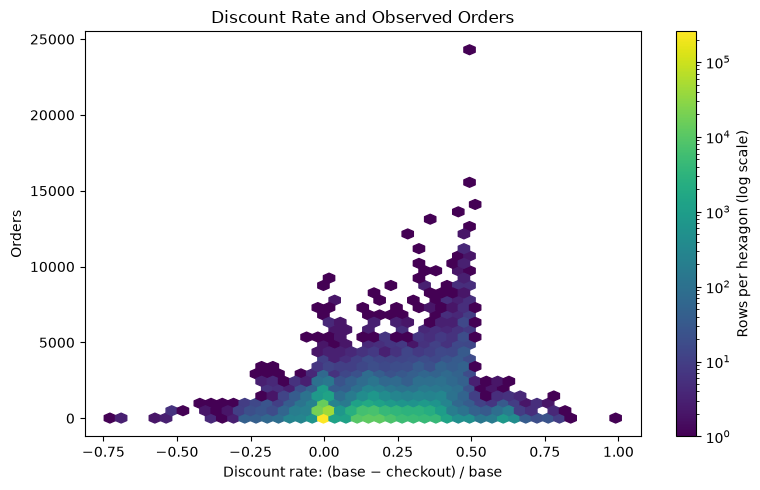

In [7]:
discount_frame = data[['base_price', 'checkout_price', 'num_orders']].copy()
valid_discount = (discount_frame['base_price'].gt(0) & np.isfinite(discount_frame['base_price']) &
                  np.isfinite(discount_frame['checkout_price']) & np.isfinite(discount_frame['num_orders']))
discount_valid = discount_frame.loc[valid_discount].copy()
discount_valid['discount_rate'] = (discount_valid['base_price'] - discount_valid['checkout_price']) / discount_valid['base_price']
excluded_discount_rows = int((~valid_discount).sum())
spearman_result = spearmanr(discount_valid['discount_rate'], discount_valid['num_orders'])
print(f'Rows tested: {len(discount_valid):,}; excluded invalid/missing rows: {excluded_discount_rows:,}.')
spearman_p_display = '< 1e-300 (underflow)' if spearman_result.pvalue == 0 else f'{spearman_result.pvalue:.6g}'
print(f'Spearman rho={spearman_result.statistic:.6f}; p-value={spearman_p_display}; n={len(discount_valid):,}.')
print('Interpretation: the sign indicates the direction of a monotonic association in these observations; it does not show that discounting caused demand to change.')
discount_result = pd.DataFrame([{'n': len(discount_valid), 'excluded_rows': excluded_discount_rows,
                                 'spearman_rho': float(spearman_result.statistic), 'p_value': float(spearman_result.pvalue),
                                 'p_value_report': spearman_p_display}])

fig, ax = plt.subplots(figsize=(8, 5))
hexes = ax.hexbin(discount_valid['discount_rate'], discount_valid['num_orders'], gridsize=45, mincnt=1,
                  bins='log', cmap='viridis')
fig.colorbar(hexes, ax=ax, label='Rows per hexagon (log scale)')
ax.set(title='Discount Rate and Observed Orders', xlabel='Discount rate: (base − checkout) / base', ylabel='Orders')
fig.tight_layout()
fig.savefig(figures_dir / 'discount_demand_association.png', dpi=160)
plt.show()
discount_result.to_csv(reports_dir / 'discount_demand_spearman.csv', index=False)

## Q6. Meal demand and volatility rankings

The meal-level table combines total orders with the distribution of weekly meal totals over observed weeks only. Standard deviation uses the sample convention (`ddof=1`); CV is SD divided by mean and is undefined when the mean is zero. Meals are ranked by total demand and by CV separately. A high CV describes relative variability and is not, by itself, poor performance. Meals in the top quartile of mean weekly demand are called high-demand for the descriptive stable-meal comparison; the five largest valid CV values are shown separately as high-volatility examples.

Top 10 meals by total demand (ties ordered by meal_id):


,meal_id,category,cuisine,total_orders,mean_weekly_orders,sd_weekly_orders,cv,observed_weeks
0,2290,Rice Bowl,Indian,9770303,67381.400000,60641.916250,0.899980,145
1,1885,Beverages,Thai,8346246,57560.317241,10998.041724,0.191070,145
2,1754,Sandwich,Italian,6818059,47021.096552,41698.021104,0.886794,145
3,1993,Beverages,Thai,6656856,45909.351724,10707.705831,0.233236,145
4,1109,Rice Bowl,Indian,6367773,43915.675862,24620.199675,0.560624,145
5,2707,Beverages,Italian,5932792,40915.806897,9760.738748,0.238557,145
6,1971,Sandwich,Italian,5728620,39507.724138,43605.509263,1.103721,145
7,2826,Sandwich,Italian,5090103,35104.158621,17059.037946,0.485955,145
8,1727,Rice Bowl,Indian,4735987,32661.979310,26274.639486,0.804441,145
9,1062,Beverages,Italian,4712795,32502.034483,6382.437463,0.196370,145


Top 10 meals by CV (ties ordered by meal_id):


,meal_id,category,cuisine,total_orders,mean_weekly_orders,sd_weekly_orders,cv,observed_weeks
0,2444,Seafood,Continental,942568,6500.468966,7833.130305,1.205010,145
1,1971,Sandwich,Italian,5728620,39507.724138,43605.509263,1.103721,145
2,1445,Seafood,Continental,1059221,7304.972414,7986.194417,1.093255,145
3,2867,Seafood,Continental,713925,4923.620690,4953.652809,1.006100,145
4,2490,Salad,Italian,3709125,29673.000000,27959.324242,0.942248,125
5,2290,Rice Bowl,Indian,9770303,67381.400000,60641.916250,0.899980,145
6,1754,Sandwich,Italian,6818059,47021.096552,41698.021104,0.886794,145
7,2104,Fish,Continental,159957,1838.586207,1513.660184,0.823274,87
8,1727,Rice Bowl,Indian,4735987,32661.979310,26274.639486,0.804441,145
9,1558,Pizza,Continental,1748940,12061.655172,9383.111367,0.777929,145


High-demand subset threshold: mean weekly orders >= 24,332.24 (75th percentile). Five most stable in that subset:


,meal_id,category,cuisine,total_orders,mean_weekly_orders,sd_weekly_orders,cv,observed_weeks
22,1885,Beverages,Thai,8346246,57560.317241,10998.041724,0.191070,145
0,1062,Beverages,Italian,4712795,32502.034483,6382.437463,0.196370,145
26,1993,Beverages,Thai,6656856,45909.351724,10707.705831,0.233236,145
46,2707,Beverages,Italian,5932792,40915.806897,9760.738748,0.238557,145
44,2664,Salad,Italian,3900812,29329.413534,12178.818057,0.415242,133


Five highest-CV meals (relative volatility; not a performance judgment):


,meal_id,category,cuisine,total_orders,mean_weekly_orders,sd_weekly_orders,cv,observed_weeks
0,2444,Seafood,Continental,942568,6500.468966,7833.130305,1.205010,145
1,1971,Sandwich,Italian,5728620,39507.724138,43605.509263,1.103721,145
2,1445,Seafood,Continental,1059221,7304.972414,7986.194417,1.093255,145
3,2867,Seafood,Continental,713925,4923.620690,4953.652809,1.006100,145
4,2490,Salad,Italian,3709125,29673.000000,27959.324242,0.942248,125


CV available for 51 of 51 meals; observed-week counts range 87–145.


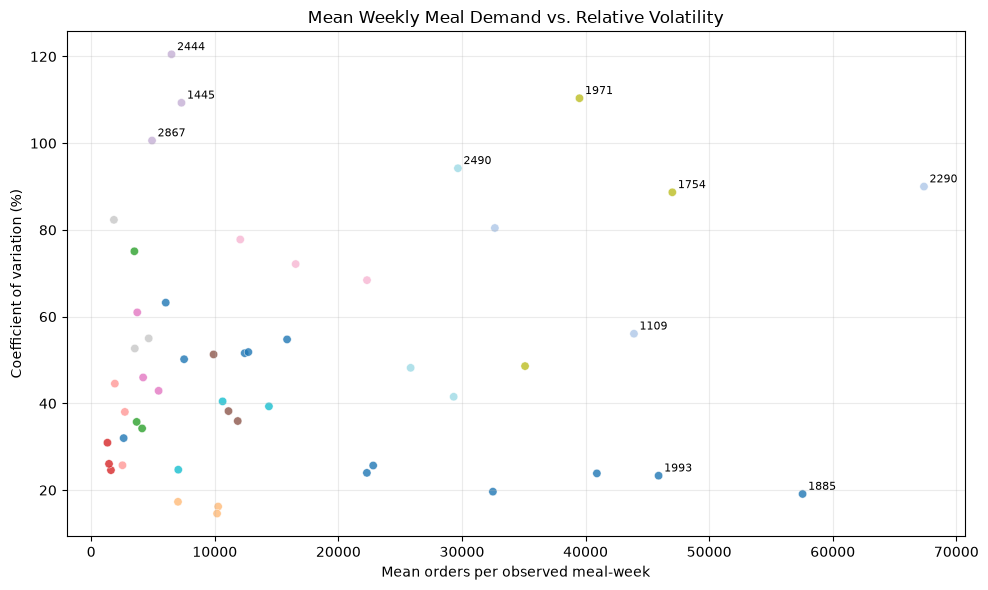

Generated figures: 14 PNG files in reports\figures.
Summary tables saved under reports/.


In [8]:
meal_total = (data.groupby('meal_id', as_index=False)
              .agg(category=('category', 'first'), cuisine=('cuisine', 'first'), total_orders=('num_orders', 'sum')))
meal_summary = meal_total.merge(meal_week_stats, on='meal_id', how='left', validate='one_to_one')
meal_summary = meal_summary[['meal_id', 'category', 'cuisine', 'total_orders', 'mean_weekly_orders',
                             'sd_weekly_orders', 'cv', 'observed_weeks']]
assert int(meal_summary['total_orders'].sum()) == total_orders, 'Meal summary does not reconcile to total orders.'
rank_total = meal_summary.sort_values(['total_orders', 'meal_id'], ascending=[False, True]).reset_index(drop=True)
rank_cv = meal_summary.dropna(subset=['cv']).sort_values(['cv', 'meal_id'], ascending=[False, True]).reset_index(drop=True)
high_demand_cutoff = meal_summary['mean_weekly_orders'].quantile(0.75)
high_demand_stable = (meal_summary.loc[meal_summary['mean_weekly_orders'].ge(high_demand_cutoff)]
                      .sort_values(['cv', 'total_orders', 'meal_id'], ascending=[True, False, True]).head(5))
high_volatility = rank_cv.head(5)
print('Top 10 meals by total demand (ties ordered by meal_id):')
display(rank_total.head(10))
print('Top 10 meals by CV (ties ordered by meal_id):')
display(rank_cv.head(10))
print(f'High-demand subset threshold: mean weekly orders >= {high_demand_cutoff:,.2f} (75th percentile). Five most stable in that subset:')
display(high_demand_stable)
print('Five highest-CV meals (relative volatility; not a performance judgment):')
display(high_volatility)
print(f'CV available for {meal_summary.cv.notna().sum()} of {len(meal_summary)} meals; observed-week counts range {meal_summary.observed_weeks.min()}–{meal_summary.observed_weeks.max()}.')

fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(meal_summary['mean_weekly_orders'], meal_summary['cv'] * 100,
                     c=pd.factorize(meal_summary['category'])[0], cmap='tab20', alpha=0.8, edgecolor='white', linewidth=0.4)
for _, row in pd.concat([rank_total.head(5), rank_cv.head(5)]).drop_duplicates('meal_id').iterrows():
    if pd.notna(row['cv']):
        ax.annotate(str(int(row['meal_id'])), (row['mean_weekly_orders'], row['cv'] * 100), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set(title='Mean Weekly Meal Demand vs. Relative Volatility', xlabel='Mean orders per observed meal-week', ylabel='Coefficient of variation (%)')
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(figures_dir / 'meal_demand_vs_volatility.png', dpi=160)
plt.show()

meal_summary.to_csv(reports_dir / 'meal_demand_volatility.csv', index=False)
rank_total.to_csv(reports_dir / 'meal_ranking_by_total_orders.csv', index=False)
rank_cv.to_csv(reports_dir / 'meal_ranking_by_cv.csv', index=False)
print(f'Generated figures: {len(list(figures_dir.glob("*.png")))} PNG files in {figures_dir.relative_to(project_root)}.')
print('Summary tables saved under reports/.')

In [9]:
peak_week = weekly_demand.loc[weekly_demand['total_orders'].idxmax()]
trough_week = weekly_demand.loc[weekly_demand['total_orders'].idxmin()]
first_week = weekly_demand.iloc[0]
last_week = weekly_demand.iloc[-1]
endpoint_change_pct = ((last_week['total_orders'] - first_week['total_orders']) / first_week['total_orders'] * 100
                      if first_week['total_orders'] != 0 else np.nan)
largest_center_type = center_type_summary.loc[center_type_summary['total_orders'].idxmax()]
emailer_result = promotion_summary.loc[promotion_summary['indicator'].eq('emailer_for_promotion')].iloc[0]
homepage_result = promotion_summary.loc[promotion_summary['indicator'].eq('homepage_featured')].iloc[0]
meal_top = rank_total.iloc[0]
most_volatile = rank_cv.iloc[0]
print('Computed findings (descriptive, not causal):')
print(f'Q1: Weekly totals ranged from {int(trough_week.total_orders):,} (week {int(trough_week.week)}) to {int(peak_week.total_orders):,} (week {int(peak_week.week)}); mean={average_weekly_demand:,.2f}. First-to-last observed-week change={endpoint_change_pct:.2f}%, which summarizes endpoints only and does not establish a sustained trend.')
print(f'Q2: {len(category_selected)} categories contributed {category_selected.demand_share.sum():.2%} of orders; {len(meal_selected)} meals contributed {meal_selected.demand_share.sum():.2%}.')
print(f'Q3: {largest_center_type.center_type} had the largest aggregate share ({largest_center_type.order_share:.2%}); center-level average weekly orders vary within types, so type totals alone do not describe a typical center.')
print(f'Metrics: total orders={total_orders:,}; estimated revenue={estimated_revenue:,.2f}; row-weighted mean signed discount={discount_rate.mean():.2%}; negative-rate rows={negative_discount_rows:,}; email-promotion rows={data.emailer_for_promotion.mean():.2%}; homepage-featured rows={data.homepage_featured.mean():.2%}.')
print(f'Q4: Email-promoted mean orders differed by {emailer_result.mean_difference_percent:.2f}% and homepage-featured mean orders by {homepage_result.mean_difference_percent:.2f}% versus their respective indicator=0 groups within eligible meal-center pairs; these are confounded observational associations, with dependent weekly rows.')
print(f'Q5: Discount rate and orders had Spearman rho={spearman_result.statistic:.4f} (n={len(discount_valid):,}; p={spearman_p_display}); this does not demonstrate a causal discount effect.')
print(f'Q6: Highest-total meal was {int(meal_top.meal_id)} ({int(meal_top.total_orders):,} orders; CV={meal_top.cv:.3f}); highest-CV meal was {int(most_volatile.meal_id)} (CV={most_volatile.cv:.3f}; {int(most_volatile.observed_weeks)} observed weeks). Missing meal-weeks were not treated as zero demand.')

Computed findings (descriptive, not causal):
Q1: Weekly totals ranged from 380,065 (week 62) to 1,303,457 (week 48); mean=824,534.38. First-to-last observed-week change=-15.19%, which summarizes endpoints only and does not establish a sustained trend.
Q2: 5 categories contributed 81.40% of orders; 22 meals contributed 81.18%.
Q3: TYPE_A had the largest aggregate share (57.69%); center-level average weekly orders vary within types, so type totals alone do not describe a typical center.
Metrics: total orders=119,557,485; estimated revenue=31,922,771,040.11; row-weighted mean signed discount=5.72%; negative-rate rows=116,101; email-promotion rows=8.12%; homepage-featured rows=10.92%.
Q4: Email-promoted mean orders differed by 147.84% and homepage-featured mean orders by 146.46% versus their respective indicator=0 groups within eligible meal-center pairs; these are confounded observational associations, with dependent weekly rows.
Q5: Discount rate and orders had Spearman rho=0.1218 (n=456

## Conclusions and limitations

Use the computed tables above to state the highest and lowest observed weekly demand, concentration needed to reach 80%, center-type shares and center-level differences, and demand/volatility rankings. Keep conclusions descriptive. The prepared observations cover different exposure patterns: absent meal-weeks are not known to be zero demand, and average center demand is divided by each center's observed weeks rather than adjusted for operation area. Estimated revenue uses listed checkout prices and order counts and is not audited revenue. Promotion tests pool weekly rows across meal-center pairs and the ordinary Mann–Whitney independence assumption is violated by repeated observations; p-values are exploratory only. Discount correlation is weak and associational, and cannot separate discounts from promotions, featured placement, seasonality, or other confounders. No causal claims or business recommendations are made in this exploratory task.

In [10]:
saved_tables = {
    'weekly_demand.csv': weekly_demand,
    'category_demand.csv': category_demand,
    'meal_total_demand.csv': meal_demand,
    'center_type_demand.csv': center_type_summary,
    'fulfilment_center_demand.csv': center_summary,
    'meal_weekly_demand.csv': weekly_meal_demand,
    'meal_demand_volatility.csv': meal_summary,
    'meal_ranking_by_total_orders.csv': rank_total,
    'meal_ranking_by_cv.csv': rank_cv,
    'promotion_demand_tests.csv': promotion_summary,
    'discount_demand_spearman.csv': discount_result,
}
for filename, expected_frame in saved_tables.items():
    saved_frame = pd.read_csv(reports_dir / filename)
    pd.testing.assert_frame_equal(saved_frame, expected_frame.reset_index(drop=True), check_dtype=False,
                                  check_exact=False, rtol=1e-10, atol=1e-10)
expected_figures = ['weekly_demand.png', 'category_demand.png', 'top_meals_demand.png',
                    'center_type_performance.png', 'promotion_demand_comparison.png',
                    'discount_demand_association.png', 'meal_demand_vs_volatility.png']
missing_figures = [name for name in expected_figures if not (figures_dir / name).is_file() or (figures_dir / name).stat().st_size == 0]
if missing_figures:
    raise FileNotFoundError(f'Missing or empty expected charts: {missing_figures}')
assert int(weekly_demand['total_orders'].sum()) == total_orders
assert int(category_demand['total_orders'].sum()) == total_orders
assert int(meal_demand['total_orders'].sum()) == total_orders
assert int(center_type_summary['total_orders'].sum()) == total_orders
assert int(meal_summary['total_orders'].sum()) == total_orders
print(f'Output audit passed: {len(saved_tables)} CSV summaries match the in-memory calculations; {len(expected_figures)} nonempty PNG charts exist; key order totals reconcile to {total_orders:,}.')

Output audit passed: 11 CSV summaries match the in-memory calculations; 7 nonempty PNG charts exist; key order totals reconcile to 119,557,485.


## Q7. Weekly demand forecast

Weekly demand is the sum of `num_orders` across all observed meal-center rows in each `week`. The notebook calls the reproducible forecasting workflow in `scripts/weekly_demand_forecast.py`: it compares row-level `LinearRegression` and `RandomForestRegressor` predictions after aggregating them to weekly totals, using the most recent 10 observed training weeks as a chronological holdout. Center and meal IDs are one-hot encoded; week, prices, and promotion/featured flags are numeric features; `id` is excluded. A fixed-origin last-training-week baseline is shown for context. The lower-MAE machine-learning model is refit on all training data and predicts each test row. Test data contains no observed target, so it is not scored.

In [11]:
import runpy
runpy.run_path(str(project_root / 'scripts' / 'weekly_demand_forecast.py'), run_name='__main__')

train.csv schema: {'id': 'int64', 'week': 'int64', 'center_id': 'int64', 'meal_id': 'int64', 'checkout_price': 'float64', 'base_price': 'float64', 'emailer_for_promotion': 'int64', 'homepage_featured': 'int64', 'num_orders': 'int64'}
test.csv schema: {'id': 'int64', 'week': 'int64', 'center_id': 'int64', 'meal_id': 'int64', 'checkout_price': 'float64', 'base_price': 'float64', 'emailer_for_promotion': 'int64', 'homepage_featured': 'int64'}
train.csv missing values: {'id': 0, 'week': 0, 'center_id': 0, 'meal_id': 0, 'checkout_price': 0, 'base_price': 0, 'emailer_for_promotion': 0, 'homepage_featured': 0, 'num_orders': 0}
test.csv missing values: {'id': 0, 'week': 0, 'center_id': 0, 'meal_id': 0, 'checkout_price': 0, 'base_price': 0, 'emailer_for_promotion': 0, 'homepage_featured': 0}
Exact duplicate rows: train=0; test=0
Training rows before weekly aggregation: 456,548
Training num_orders before weekly aggregation: 119,557,485
Weekly aggregates: 145 chronologically sorted observed weeks


Holdout evaluation (weekly total MAE; lower is better):
                      model weekly_total_mae
           LinearRegression        70,614.65
      RandomForestRegressor        28,735.96
Last training week baseline        41,012.80

Selected machine-learning model: RandomForestRegressor (holdout weekly MAE 28,735.96 orders, weeks 136–145).
Naive baseline weekly MAE: 41,012.80 orders (repeats week 135 total for each holdout week).


test.csv has no num_orders column; no test-file MAE was calculated.
Saved 32,573 row-level test forecasts (10 weeks) to reports/weekly_demand_test_predictions.csv.
Saved holdout comparison, holdout weekly predictions, test weekly totals, and holdout chart under reports/.


{'__name__': '__main__',
 '__doc__': None,
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\SHOQG\\Desktop\\Data\\AI\\food-demand-analysis\\scripts\\weekly_demand_forecast.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=<class '_frozen_importlib.BuiltinImporter'>, origin='built-in'),
  '__build_class__': <function __build_class__>,
  '__import__': <function __import__(